**Nombre completo:** **Noriega Velazquez Jesus Manuel**

**Grupo:** **002**

**Fecha:** **14/10/2026**

---

# Laboratorio · Variables continuas con NumPy
**Simulación de Sistemas · Miércoles 14 de octubre de 2026 · segunda hora**

En la primera hora hicimos uniforme, exponencial y normal con `random`. Ahora las comparamos contra las funciones de NumPy. Al final simulamos la ventanilla del banco con 10 clientes.

## 0. Preparación
Fijamos una semilla para que los resultados se puedan reproducir.

In [2]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
print("NumPy", np.__version__)

NumPy 1.26.4


## 1. Repaso: nuestras funciones de la primera hora
Estas son las mismas funciones de la presentación, con `random`.

In [4]:
def uniforme(a, b):
    return a + (b - a) * random.random()

def exponencial(lam):
    u = random.random()
    return -math.log(1 - u) / lam

def normal(mu, sigma):
    u1 = random.random()
    u2 = random.random()
    r = math.sqrt(-2*math.log(1-u1))
    z = r * math.cos(2*math.pi*u2)
    return mu + sigma * z

random.seed(2026)
print(uniforme(2, 8), exponencial(0.5), normal(10, 2))

2.7147193097837787 1.3963827833829814 11.526715536883101


## 2. Las funciones de NumPy
Ahora generamos 10 000 valores de cada distribución con NumPy.

> **Cuidado:** `np.random.exponential` recibe `scale = 1/λ`, no λ. Con λ = 0.5 el `scale` es 2.

In [6]:
N = 10_000
lam = 0.5

u_np = rng.uniform(2, 8, N)
e_np = rng.exponential(scale=1/lam, size=N)   # scale = 1/λ
n_np = rng.normal(loc=10, scale=2, size=N)    # loc = μ, scale = σ

print("uniforme   media:", u_np.mean().round(3))
print("exponencial media:", e_np.mean().round(3))
print("normal     media:", n_np.mean().round(3))

uniforme   media: 5.032
exponencial media: 1.975
normal     media: 9.998


## 3. Validación: media y varianza contra la teoría
| Distribución | Media teórica | Varianza teórica |
|---|---|---|
| Uniforme(a, b) | (a + b) / 2 | (b − a)² / 12 |
| Exponencial(λ) | 1 / λ | 1 / λ² |
| Normal(μ, σ) | μ | σ² |

In [8]:
tabla = [
    ("Uniforme(2,8)", u_np, 5, 36/12),
    ("Exponencial(λ=0.5)", e_np, 1/lam, 1/lam**2),
    ("Normal(10,2)", n_np, 10, 4),
]
for nombre, datos, media_t, var_t in tabla:
    print(f"{nombre:22s} media {datos.mean():7.3f} (teórica {media_t:6.3f})   "
          f"varianza {datos.var():7.3f} (teórica {var_t:6.3f})")

Uniforme(2,8)          media   5.032 (teórica  5.000)   varianza   2.990 (teórica  3.000)
Exponencial(λ=0.5)     media   1.975 (teórica  2.000)   varianza   3.964 (teórica  4.000)
Normal(10,2)           media   9.998 (teórica 10.000)   varianza   3.946 (teórica  4.000)


## 4. Histogramas lado a lado
Nuestra función (`random`) contra la de NumPy, para cada distribución.

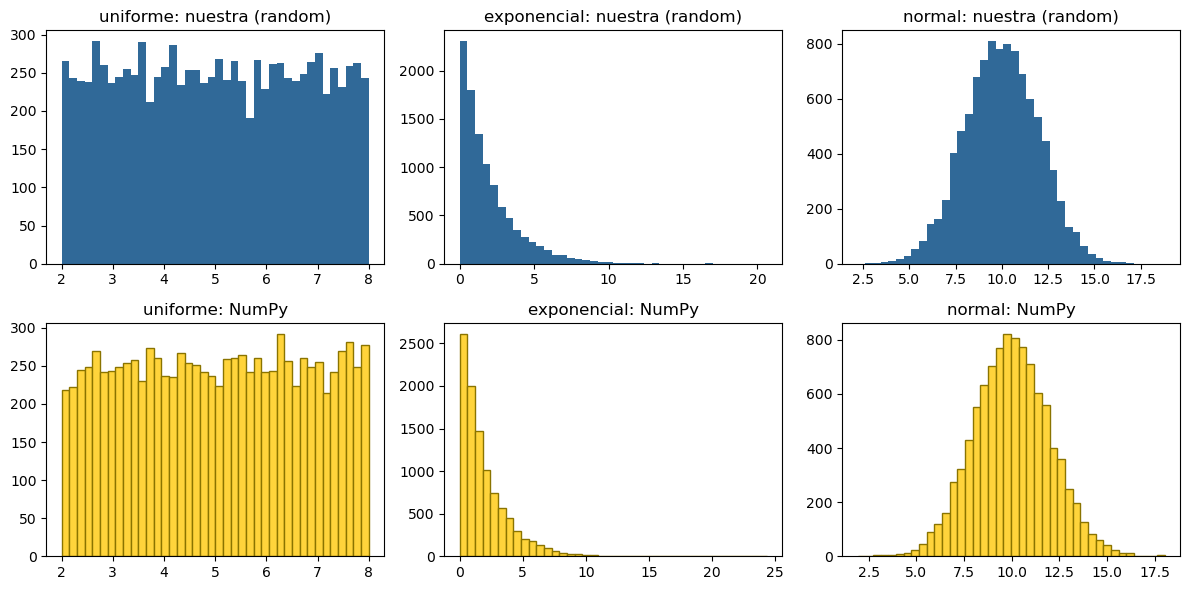

In [10]:
random.seed(7)
nuestra = {
    "uniforme": [uniforme(2, 8) for _ in range(N)],
    "exponencial": [exponencial(lam) for _ in range(N)],
    "normal": [normal(10, 2) for _ in range(N)],
}
numpy_ = {"uniforme": u_np, "exponencial": e_np, "normal": n_np}

fig, ejes = plt.subplots(2, 3, figsize=(12, 6))
for j, k in enumerate(nuestra):
    ejes[0, j].hist(nuestra[k], bins=40, color="#306998")
    ejes[0, j].set_title(f"{k}: nuestra (random)")
    ejes[1, j].hist(numpy_[k], bins=40, color="#FFD43B", edgecolor="#8a7400")
    ejes[1, j].set_title(f"{k}: NumPy")
plt.tight_layout()
plt.show()

## 5. Ejercicio de cierre: la ventanilla
Un banco tiene una sola ventanilla.
- Llegadas: tiempo entre llegadas exponencial con media de 2 minutos.
- Servicio: tiempo de atención uniforme entre 1 y 4 minutos.
- Cada cliente espera su turno: inicio = el mayor entre su llegada y el fin del cliente anterior.

Simulamos 10 clientes en cada corrida y repetimos 1 000 corridas.

In [12]:
def corrida(n_clientes=10):
    entre_llegadas = rng.exponential(scale=2, size=n_clientes)
    servicio = rng.uniform(1, 4, size=n_clientes)
    llegada = np.cumsum(entre_llegadas)    # minuto en que llega cada cliente
    inicio = np.empty(n_clientes)
    fin = np.empty(n_clientes)
    for i in range(n_clientes):
        inicio[i] = max(llegada[i], fin[i-1]) if i > 0 else llegada[i]
        fin[i] = inicio[i] + servicio[i]
    espera = inicio - llegada
    return espera.mean()

esperas = np.array([corrida() for _ in range(1000)])
print("Espera promedio por cliente, promedio de 1 000 corridas:", esperas.mean().round(3), "min")
print("Desviación entre corridas:", esperas.std().round(3), "min")

Espera promedio por cliente, promedio de 1 000 corridas: 3.683 min
Desviación entre corridas: 2.045 min


**Para discutir:** si cambiamos el servicio a uniforme entre 1 y 5 minutos, ¿la espera promedio sube o baja? Cambia la línea de `servicio` y vuelve a correr la celda.


**Respuesta:** La espera promedio sube.¿Por qué ocurre esto? 
- Con el intervalo de servicio original entre 1 y 4 minutos, el tiempo promedio que se pasa atendiendo a cada cliente es de 2.5 minutos $\left(\frac{1 + 4}{2}\right)$.
- Al cambiar el servicio a un uniforme entre 1 y 5 minutos, el tiempo medio de atención aumenta a 3.0 minutos $\left(\frac{1 + 5}{2}\right)$.
- Al requerir más tiempo por cliente, el sistema se satura con mayor facilidad, lo que incrementa las filas y hace que la espera promedio en el banco sea mayor.